# Day II - C) 3D magneto-quasistatics

- **<font color='green'>[RUN & OBSERVE]</font>** $\rightarrow$ the cell should be run directly without modification
- **<font color='orange'>[RUN & PLAY]</font>** $\rightarrow$ the cell can be run directly, but some parameters should be changed interactively
- **<font color='red'>[FILL & RUN]</font>**    $\rightarrow$ the cell should be filled before being run
- **<font color='magenta'>[FILL & PLAY]</font>** $\rightarrow$ the cell should be filled, and then some parameters should be changed interactively.

_____

Unlike magnetostatics, which assumes **steady currents** $J_s$ and solves $\operatorname{curl}(\nu\operatorname{curl}A)=J_s$, magnetoquasistatics accounts for time-varying fields and **induced currents** (while still neglecting displacement currents).

For the $A$-$V$ formulation, neglecting displacement currents, the strong equations in a conducting domain $\Omega$ read

$$
\begin{aligned}
\operatorname{curl}(\nu \operatorname{curl} A)
+\overbrace{\sigma\left(\frac{\partial A}{\partial t}
+\operatorname{grad}V\right)}^{\text{Ohm Law}}&=J_s,\\
\operatorname{div}\left[
J_s-\sigma\left(\frac{\partial A}{\partial t}
+\operatorname{grad}V\right)\right]&=0,
\end{aligned}
$$

where $\nu$ is the magnetic reluctivity, $\sigma$ the electrical conductivity, and $J_s$ the impressed current density. The corresponding weak form of the first equation is to find $A$ and $V$ such that, for all test functions $w\in H(\operatorname{curl},\Omega)$,

$$
\begin{aligned}
&\int_\Omega \operatorname{curl}w\cdot
(\nu\operatorname{curl}A)\,\mathrm{d}\Omega +\int_\Omega w\cdot\sigma
\left(\frac{\partial A}{\partial t}
+\operatorname{grad}V\right)\,\mathrm{d}\Omega
=\int_\Omega w\cdot J_s\,\mathrm{d}\Omega.
\end{aligned}
$$

As $\operatorname{curl}(\operatorname{grad}u)=0$, the transformation $A\mapsto A+\operatorname{grad}u$ leaves the magnetic flux density unchanged. The electric scalar potential must simultaneously transform as $V\mapsto V-\partial u/\partial t$ to preserve the electric field. This gauge invariance introduces a non-uniqueness that may require an additional gauge condition or regularization strategy.

## 1) Geometry and properties
We start by defining the 3D geometry and mesh from [TEAM problem 15](https://www.compumag.org/jsite/images/stories/TEAM/problem15.pdf).

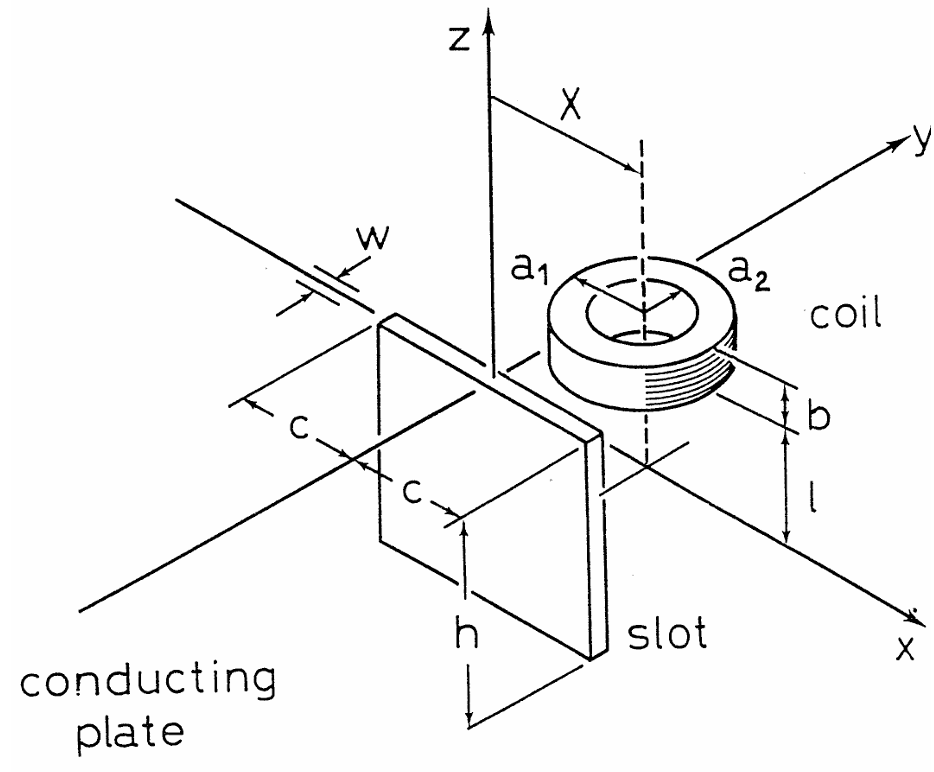

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [5]:
import ngsolve
import scipy
from utils.myGeometries import team15_geometry

geoOCC = team15_geometry(
    EXPERIMENT=1,
    symmetry=1,
    draw=True
)

In [6]:
from ngsolve import Mesh
from ngsolve.webgui import Draw
Omega = Mesh(geoOCC.GenerateMesh(maxh=0.1))
print(f"meshed with {Omega.ne} elements, {Omega.nv} nodes, {Omega.nedge} edges")
Draw(Omega)

meshed with 129997 elements, 22303 nodes, 152705 edges


WebGLScene

In [7]:
print(f"Faces and boundaries: {Omega.GetBoundaries()}")
print(f"Regions: {Omega.GetMaterials()}")

Faces and boundaries: ('default', 'default', 'slot', 'default', 'default', 'default', 'slot', 'slot', 'slot', 'slot', 'slot', 'default', 'default', 'default', 'default', 'outer')
Regions: ('plate', 'coil', 'air')


### b) Material properties

Then, we define reluctivity and current density fields. We assume iron is linear with $\mu_r = 1000$ to avoid long computation time, and $J = 1A/mm^2$.

|**<font color='red'>[FILL & RUN]</font>** |
|---|

In [ ]:

from ngsolve import pi, Normalize, CoefficientFunction, x, y

I=1

# coil dimension (from TEAM 15 data sheet)
a2 = 6.15e-3
a1 = 12.4e-3
b = 6.15e-3
N = 3790
Scoil = (a1 - a2) * b

J = I*N/Scoil
f = 900 # 1.7e3
jw = 1j*2*pi*f
mu0 = 4e-7 * pi
sigma_conductor = 30.6e6
sigma = Omega.MaterialCF({"plate": sigma_conductor})  # aussi dans la bobine?
jsource =  Omega.MaterialCF({"coil" : J*Normalize(CoefficientFunction((-y,x,0)))})

#-----------------------------------------------------------------------------------------------
# Show the current
from ngsolve import L2, GridFunction
jL2 = GridFunction(L2(Omega, dim = 3))
jL2.Set(jsource)

clipcoil= { "pnt" : (0,0,0), "vec" : (0,0,-1), "dist" : 5e-3 }
Draw(jL2, Omega, vectors={"grid_size" : 100} , 
     clipping = clipcoil
     )

WebGLScene

## 2) Resolution

The $A-V$ formulation reads: $\forall a^*,v^* \in H_0(\text{curl},\Omega)\times H^1_*(\Omega)$,
$$
\left \{
\begin{array}{lclcl}
\displaystyle \int_\Omega (\nu \, \text{curl}~a) \cdot \text{curl}~a^*  & + & \displaystyle \int_\Omega \sigma (j\omega a + \text{grad}\,v) \cdot a^* & = & \displaystyle \int_\Omega a^* \cdot j \\
\displaystyle \int_\Omega  \sigma j\omega a \cdot \text{grad}\, v^* & + & \displaystyle \int_\Omega  \sigma \text{grad}\,v \cdot \text{grad}\, v^* & = & 0
\end{array} \right.
$$


### a) Wrapper

We can use several solvers type. Since the matrix is not symmetric we should use:
- **direct solver** : LU factorization with `superlu`
- **iterative solver** : GMRES using `gmres`

Moreover for iterative solver we can use preconditioners. Only Jacobi preconditioner called `local` is interesting in our case.

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [9]:
from utils.mySolvers import mySolver
help(mySolver)

Help on function mySolver in module utils.mySolvers:

mySolver(
    bilinearform,
    linearform,
    type: str = 'sparsecholesky',
    preconditioner: str = None,
    atol: float = 1e-10,
    rtol: float = 1e-10,
    maxiter: int = 1000,
    display: bool = False,
    detailed_result=False,
    restart: int = 50
) -> ngsolve.comp.GridFunction
    Solve a linear variational problem using direct or iterative methods.

    This function handles both direct and iterative approaches for solving the discrete system
    derived from finite element formulations. Direct solvers (sparsecholesky, superlu) factorize the
    matrix directly, while iterative solvers require careful convergence criteria handling.

    Parameters:
        bilinearform: The NGSolve bilinear form defining the left-hand side of the equation.
                      Must be associated with a finite element space and support necessary methods.
        linearform:   The NGSolve linear form representing the right-hand side of

### b) Iterative solver

We have seen that iterative solver are generally more interesting in 3D. The best approach is to consider a conforming right hand side (and forget about gauging). 


#### i) Current projection 
Actually, the current should be divergence free. It is not the case at the discrete level; but we can enforce this easily by expressing the current density as $j = \text{curl}\,t$. This can be done by solving first an auxiliary problem (that naturally have a compatible RHS):

$$ \text{Find}~ t \in H_0(\text{curl},\Omega), ~\text{such that}~ \forall v \in H_0(\text{curl},\Omega), \quad \int_\Omega \text{curl}~ v \cdot \text{curl}~ t = \int_\Omega \text{curl}~v \cdot j $$

This problem is symmetric positive definite and well conditioned. The more efficient solver is conjugated gradient.

|**<font color='red'>[FILL & RUN]</font>** |
|---|

In [10]:
from ngsolve import HCurl, BilinearForm, LinearForm, curl, dx

def project_current(jsource, fes):
     """Project the current j onto the finite element space fes."""
     t, v = fes.TnT()
     Aj = BilinearForm(curl(t) * curl(v) * dx)
     fj = LinearForm(curl(v) * jsource * dx("coil"))
     return mySolver(Aj, fj, type = "cg", 
                     preconditioner="local", maxiter = 10000)


fesT = HCurl(Omega, order = 0, dirichlet = "outer")
#fesT = HCurl(Omega, order = 2, dirichlet = "outer", nograds = True)
sol_t = project_current(jsource, fesT)

Draw(curl(sol_t), Omega, vectors={"grid_size" : 100} , 
     clipping = clipcoil)

Converged in 267 iterations (residual = 9.8182e-11)


WebGLScene

A way to find the global current is to integrate $T$ along a path that encloses the coil. Another way is to integrate along the current lines (easier to code).

In [11]:
from ngsolve import Integrate


def current(jsource, N = N):
    """ Current in the coil """
    volCoil = Integrate(1, Omega.Materials("coil"))
    lCoil = volCoil / Scoil
    I = Integrate( jsource * Normalize(curl(sol_t)), Omega.Materials("coil")) / (lCoil * N)
    return I


#I = current(curl(sol_t))
#print(f"I = {I*1e3  :.1f} mA")

#### ii) Solve magnetoquasistatic with GMRes

Then we simply solve $\forall a^*,v^* \in H_0(\text{curl},\Omega)\times H^1_*(\Omega_c)$:
$$
\left \{
\begin{array}{lll}
\displaystyle \int_\Omega (\nu \, \text{curl}~a) \cdot \text{curl}~a^* + \sigma j\omega a \cdot a^* &+ \displaystyle \int_\Omega \sigma \, \text{grad}\,v \cdot a^* & =\displaystyle \int_\Omega a^* \cdot \text{curl}\, t \\
\displaystyle \int_\Omega  \sigma j\omega a \cdot \text{grad}\, v^*  &+ \displaystyle \int_\Omega  \sigma \,  \text{grad}\,v \cdot \text{grad}\, v^*  & = 0
\end{array}
\right.
$$

We can't use conjugate anymore (not hermitian). We switch to [GMRES](https://en.wikipedia.org/wiki/Generalized_minimal_residual_method) solver. Since the cost of each iteration increases linearly with the number of iteration, we have to "restart" it from time to time.

|**<font color='magenta'>[FILL & PLAY]</font>**|
|---|

Converged in 1 iterations (residual = 1.8210e-13)


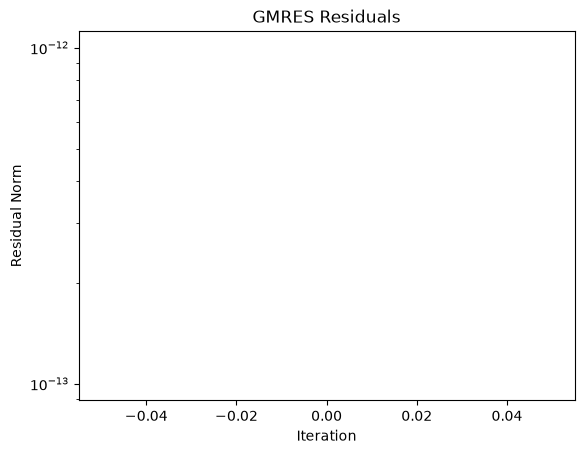

In [12]:
def solve_magnetoquasistatic(fes_a,  # finite element space of vector potential
                             fes_v,  # finite element space of scalar potential
                             T,      # current vector potential
                             *args, **kwargs # solver parameters
                             ):
    """Solve the magnetoquasistatic problem with gmres."""

    fes = fes_a*fes_v

    a, v = fes.TrialFunction()
    a_, v_ = fes.TestFunction()

    Aav = BilinearForm(fes)
    Aav += 1/mu0 * curl(a) * curl(a_) * dx
    Aav += sigma * (jw * a + grad(v)) * a_ * dx("plate")
    Aav += sigma * (jw * a + grad(v)) * grad(v_) * dx("plate")

    fav = LinearForm(fes)
    fav += a_* curl(T) * dx       # not dx("coil") !!!!
    # fa = LinearForm(curl(v) * sol_t * dx)  # work as well

    return mySolver(Aav, fav, type = "gmres", preconditioner="local",
                    *args, **kwargs)


from ngsolve import H1, HCurl, grad

fes_v = H1(Omega, order = 1,  definedon = "plate", complex = True)
fes_v.FreeDofs()[0] = 0

fes_a = HCurl(Omega, order = 0, dirichlet = "outer", complex = True)
#fes_a = HCurl(Omega, order = 2, dirichlet = "outer", complex = True, nograds = True)

result_gmres = solve_magnetoquasistatic(fes_a, fes_v, sol_t,
                                        maxiter = 500, 
                                        atol = 1e-10,
                                        restart = 75,  # restart decreases the cost per iteration, but increases the number of iterations.
                                        detailed_result = True)

sol_av_gmres = result_gmres["solution"]

import matplotlib.pyplot as plt
plt.semilogy(result_gmres["residuals"])
plt.title("GMRES Residuals")
plt.xlabel("Iteration"); plt.ylabel("Residual Norm")
plt.show()

#### iii) Draw result

In [13]:
def current_density(sol):
    """ Current density """
    return - sigma_conductor * (jw*sol.components[0] + grad(sol.components[1]))


from ngsolve.webgui import FieldLines
from ngsolve import VectorH1

def draw3D(field, clip, mesh = Omega, region=Omega.Materials(".*")):
    """ Draw 3D field """
    if field.dim == 3:
        fieldVectorH1 = GridFunction(VectorH1(mesh, order = 2, complex = True, definedon = region))
        fieldVectorH1.Set(field)
        fieldlines = FieldLines(field, region,
                            length=0.5, num_lines=100,
                            thickness = 0.0002)
        Draw(fieldVectorH1, mesh, 
            objects=[fieldlines],
            vectors={"grid_size" : 50}, 
            settings = {"Objects": {"Surface": False}},
            clipping = clip)
    else:
        Draw(field, mesh, settings = {"Objects": {"Clipping Plane": True}}, clipping = clip)


clipB= { "pnt" : (0,0,0), "vec" : (0,1,0) , "dist" : -1e-4 }
clipJ = { "pnt" : (0,0,0), "vec" : (0,0,-1), "dist": -1e-4 }

In [14]:
# Uncomment to draw

#print("B (T)");  draw3D(curl(sol_av_gmres.components[0]).real, clip = clipB)
print("J (A/m²)"); draw3D(current_density(sol_av_gmres).real, region=Omega.Materials("plate"), clip = clipJ)
#print("J (A/m²) - A component"); draw3D((- sigma_conductor * jw*sol_av_gmres.components[0] ).real, region=Omega.Materials("plate"), clip = clipJ)
#print("J (A/m²) - V component"); draw3D(- sigma_conductor * grad(sol_av_gmres.components[1] ).real, region=Omega.Materials("plate"), clip = clipJ)
#print("V (V)");  draw3D(sol_av_gmres.components[1].real,  region=Omega.Materials("plate"), clip = clipJ)

J (A/m²)
Warning in Webgui.Draw: function has more than 3 components, drawing Norm(cf) instead


### c) Symmetries

3D computation can be quite long. Meshing and computation time can be drastically reduced by exploiting symmetries to reduce the computational domain. Appropriate boundary conditions have to be chosen on the symmetry / anti-symmetry cut planes.

In [15]:
sym_fac = 4

geoOCC_sym = team15_geometry(
    EXPERIMENT=1,
    symmetry=sym_fac,
    draw=False,
)

Omega_sym = Mesh(geoOCC_sym.GenerateMesh(maxh=0.1))
print(f"meshed with {Omega_sym.ne} elements, {Omega_sym.nv} nodes, {Omega_sym.nedge} edges")
Draw(Omega_sym)
print(f"Faces: {Omega_sym.GetBoundaries()}")
print(f"Regions: {Omega_sym.GetMaterials()}")

meshed with 6168 elements, 1339 nodes, 8038 edges


Faces: ('default', 'default', 'default', 'sym_y', 'slot', 'slot', 'sym_x', 'default', 'slot', 'default', 'default', 'sym_x', 'default', 'sym_y', 'default', 'outer', 'sym_x', 'sym_y')
Regions: ('plate', 'coil', 'air')


Since we don't have a lot of DoFs we can play with the order.

Don't forget to set `nograds` to `true` in this case: cancel the gradient part within each element (possible due to hierarchical structure of elements in NGSolve).

In [16]:
# Current projection

global_order = 2

j_source_sym =  Omega_sym.MaterialCF({"coil" : J*Normalize(CoefficientFunction((-y,x,0)))})
fesT_sym = HCurl(Omega_sym, order = global_order, dirichlet = "outer", nograds = True if global_order else False)
sol_t_sym = project_current(j_source_sym, fesT_sym)
Draw(curl(sol_t_sym), Omega_sym, vectors={"grid_size" : 100} ,
     clipping = clipcoil)

Converged in 208 iterations (residual = 9.4231e-11)


WebGLScene

Converged in 1 iterations (residual = 3.2087e-13)


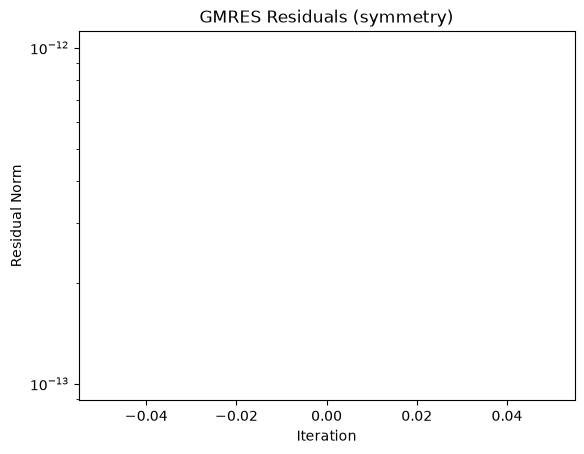

In [17]:
# Magnetoquasistatic problem on the symmetric domain

fesV_sym = H1(Omega_sym, order = global_order, definedon = "plate", dirichlet = "sym_y|sym_x", complex = True)
fesA_sym = HCurl(Omega_sym, order = global_order, dirichlet = "outer|sym_y|sym_x", complex = True, nograds = True if global_order else False)


result_gmres_sym = solve_magnetoquasistatic(fesA_sym, fesV_sym, sol_t_sym,
                                           maxiter = 500, 
                                           atol = 1e-10,
                                           restart = 100,  # restart decreases the cost per iteration, but increases the number of iterations.
                                           detailed_result = True)

sol_av_gmres_sym = result_gmres_sym["solution"]

import matplotlib.pyplot as plt
plt.semilogy(result_gmres_sym["residuals"])
plt.title("GMRES Residuals (symmetry)")
plt.xlabel("Iteration"); plt.ylabel("Residual Norm")
plt.show()

####  Display results

In [18]:
#print("B (T)");  draw3D(curl(sol_av_gmres_sym.components[0]).real, mesh = Omega_sym, clip = clipB)
print("J (A/m²)"); draw3D(current_density(sol_av_gmres_sym).real, mesh = Omega_sym, region=Omega_sym.Materials("plate"), clip = clipJ)
#print("J (A/m²) - A component"); draw3D((- sigma_conductor * jw*sol_av_gmres_sym.components[0] ).real, mesh = Omega_sym, region=Omega_sym.Materials("plate"), clip = clipJ)
#print("J (A/m²) - V component"); draw3D(- sigma_conductor * grad(sol_av_gmres_sym.components[1] ).real, mesh = Omega_sym, region=Omega_sym.Materials("plate"), clip = clipJ)
#print("V (V)");  draw3D(sol_av_gmres_sym.components[1].real, mesh = Omega_sym,  region=Omega_sym.Materials("plate"), clip = clipJ)

J (A/m²)


Warning in Webgui.Draw: function has more than 3 components, drawing Norm(cf) instead


## 4) Post-processing: nondestructive control

In non destructive control, we measure the variations of resistance and inductance. There are several way to compute them numerically:

- From the dissipated power and stored magnetic energy
- From the flux

In [19]:
from ngsolve import Integrate, InnerProduct

def L(sol):
    """ Inductance from magnetic energy """
    mesh = sol.space.components[0].mesh
    B = curl(sol.components[0])
    QoverW = Integrate( InnerProduct(B, B) / mu0, mesh).real
    return  QoverW / I**2

def R(sol):
    """ Resistance from dissipated power """
    mesh = sol.space.components[0].mesh
    J = current_density(sol)
    P = (Integrate(InnerProduct(J,J)/sigma_conductor , mesh.Materials("plate"))).real
    return P / I**2


print(f" R      = {R(sol_av_gmres) :.1f} Ohm")
print(f" R_sym  = {4*R(sol_av_gmres_sym) :.1f} Ohm")
print(f" L      = {L(sol_av_gmres) * 1e3 :.3f} mH")
print(f" L_sym  = {4*L(sol_av_gmres_sym) * 1e3 :.3f} mH")

 R      = 0.0 Ohm
 R_sym  = 0.0 Ohm
 L      = 0.000 mH
 L_sym  = 0.000 mH


- Is $R$ in series or parallel? => series

From the flux : TODO

In [20]:
def flux_linkage(sol_A, T, region, I):
    """λ = ∫ A·J_s dV / I, with J_s = curl(T): exactly consistent with the source in the RHS."""
    return Integrate(sol_A * curl(T), region) / I

lam     = flux_linkage(sol_av_gmres.components[0], sol_t, Omega.Materials("coil"), I)
lam_sym = 4 * flux_linkage(sol_av_gmres_sym.components[0], sol_t_sym, Omega_sym.Materials("coil"), I)

V_full = jw * lam
V_sym  = jw * lam_sym

In [21]:
real_im = lambda s : f"{s.real:.3e} + {s.imag:.3e}j"
print(f"voltage     = {real_im(V_full)} V")
print(f"voltage_sym = {real_im(V_sym)} V")

voltage     = 0.000e+00 + 0.000e+00j V
voltage_sym = 0.000e+00 + 0.000e+00j V


In [22]:
print(f"R     = {V_full.real/I :.3f} Ohm")
print(f"R_sym = {V_sym.real/I:.3f} Ohm")

print(f"L     = {V_full.imag/I / (2*pi*f)*1000 :.3f} mH")
print(f"L_sym = {V_sym.imag/I/ (2*pi*f)*1000 :.3f} mH")

R     = 0.000 Ohm
R_sym = 0.000 Ohm
L     = 0.000 mH
L_sym = 0.000 mH


In [23]:
print(Integrate(curl(sol_t) * sol_av_gmres.components[0], Omega))
print(Integrate(InnerProduct(current_density(sol_av_gmres),current_density(sol_av_gmres)) / sigma_conductor , Omega.Materials("plate"))/  -jw)

0j
(-0-0j)


In [24]:
jw

5654.8667764616275j

## References

- [TEAM Workshop Problem 15 (1997)](https://www.compumag.org/jsite/images/stories/TEAM/problem15.pdf)